# __Hospital Stay Preiction__

# 1. Business Case

The objective of this analysis is to predict the duration of a patient's hospital stay (Stay) based on various features such as hospital attributes (type, region, available rooms), patient demographics (age, city), and admission details (severity of illness, department, admission deposit). Accurate predictions will help hospitals optimize bed management and resource allocation.

In [1]:
## import important Libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
# load Data
df = pd.read_csv('HealthCareAnalytics.csv')

In [3]:
df.head()

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558,41-50


# 2. Basic Checks

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318438 entries, 0 to 318437
Data columns (total 18 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   case_id                            318438 non-null  int64  
 1   Hospital_code                      318438 non-null  int64  
 2   Hospital_type_code                 318438 non-null  object 
 3   City_Code_Hospital                 318438 non-null  int64  
 4   Hospital_region_code               318438 non-null  object 
 5   Available_Extra_Rooms_in_Hospital  318438 non-null  int64  
 6   Department                         318438 non-null  object 
 7   Ward_Type                          318438 non-null  object 
 8   Ward_Facility_Code                 318438 non-null  object 
 9   Bed_Grade                          318325 non-null  float64
 10  patientid                          318438 non-null  int64  
 11  City_Code_Patient                  3139

In [5]:
df.describe()

,case_id,Hospital_code,City_Code_Hospital,Available_Extra_Rooms_in_Hospital,Bed_Grade,patientid,City_Code_Patient,Visitors_with_Patient,Admission_Deposit
count,318438.000000,318438.000000,318438.000000,318438.000000,318325.000000,318438.000000,313906.000000,318438.000000,318438.000000
mean,159219.500000,18.318841,4.771717,3.197627,2.625807,65747.579472,7.251859,3.284099,4880.749392
std,91925.276847,8.633755,3.102535,1.168171,0.873146,37979.936440,4.745266,1.764061,1086.776254
min,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1800.000000
25%,79610.250000,11.000000,2.000000,2.000000,2.000000,32847.000000,4.000000,2.000000,4186.000000
50%,159219.500000,19.000000,5.000000,3.000000,3.000000,65724.500000,8.000000,3.000000,4741.000000
75%,238828.750000,26.000000,7.000000,4.000000,3.000000,98470.000000,8.000000,4.000000,5409.000000
max,318438.000000,32.000000,13.000000,24.000000,4.000000,131624.000000,38.000000,32.000000,11008.000000


In [6]:
df.describe(include='O')

,Hospital_type_code,Hospital_region_code,Department,Ward_Type,Ward_Facility_Code,Type_of_Admission,Severity_of_Illness,Age,Stay
count,318438,318438,318438,318438,318438,318438,318438,318438,318438
unique,7,3,5,6,6,3,3,10,11
top,a,X,gynecology,R,F,Trauma,Moderate,41-50,21-30
freq,143425,133336,249486,127947,112753,152261,175843,63749,87491


# 3. Exploratory Data Analysis (EDA)

### 3.1 Missing value Analysis

                   Missing Count  Missing %
Bed_Grade                    113       0.04
City_Code_Patient           4532       1.42


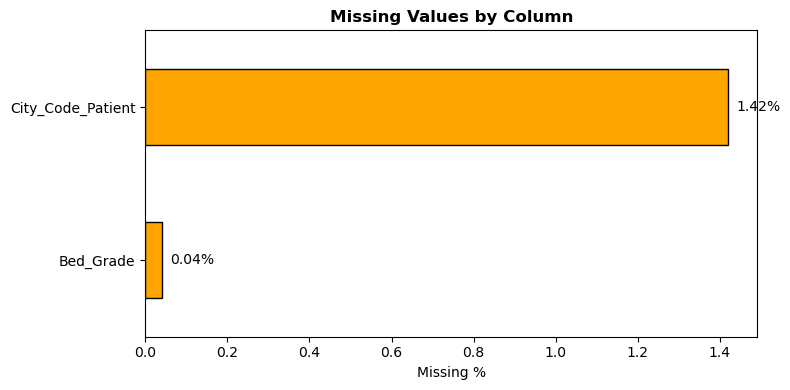

In [7]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count' : missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0]
print(missing_df)

fig, ax = plt.subplots(figsize=(8,4))
missing_df['Missing %'].plot(kind='barh', ax=ax, color='orange', edgecolor= 'black')
ax.set_xlabel('Missing %')
ax.set_title('Missing Values by Column', fontweight='bold')
for i, v in enumerate(missing_df['Missing %']):
    ax.text(v + 0.02, i, f'{v :.2f}%', va = 'center', fontsize=10)
plt.tight_layout()
plt.show()

### 3.2 Target Variable- Length of Stay Distribution

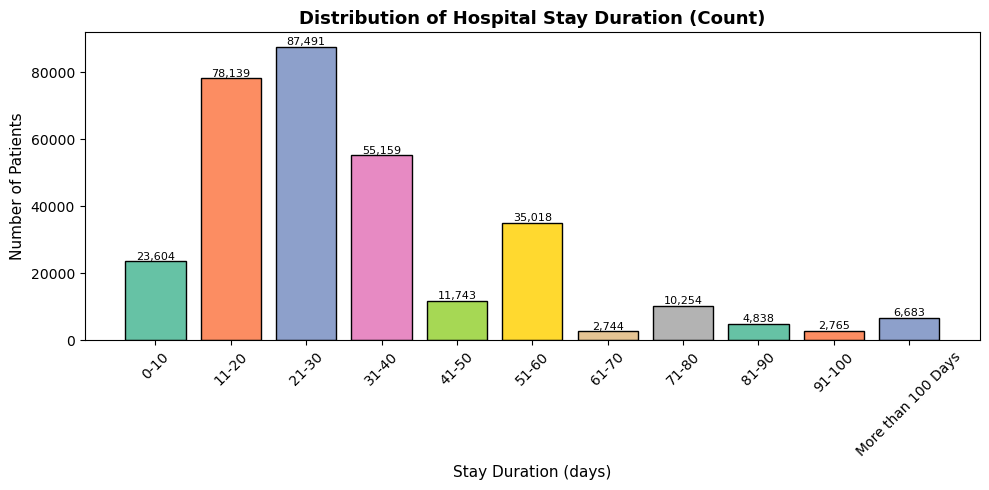

Stay
0-10                  23604
11-20                 78139
21-30                 87491
31-40                 55159
41-50                 11743
51-60                 35018
61-70                  2744
71-80                 10254
81-90                  4838
91-100                 2765
More than 100 Days     6683
Name: count, dtype: int64


In [8]:
# Fix Excel date-corruption: 'Nov-20' is actually '11-20'
df['Stay'] = df['Stay'].replace('Nov-20', '11-20')

stay_order = ['0-10','11-20','21-30','31-40','41-50',
              '51-60','61-70','71-80','81-90','91-100','More than 100 Days']
stay_counts = df['Stay'].value_counts().reindex(stay_order)


plt.figure(figsize=(10, 5))

# Single Bar Plot for Counts
bars = plt.bar(stay_counts.index, stay_counts.values, color=sns.color_palette("Set2", 11), edgecolor='black')
plt.xlabel('Stay Duration (days)', fontsize=11)
plt.ylabel('Number of Patients', fontsize=11)
plt.title('Distribution of Hospital Stay Duration (Count)', fontsize=13, fontweight='bold')
plt.xticks(rotation=45)

# showing a value on a bars
for bar, val in zip(bars, stay_counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 500, f'{val:,}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()
print(stay_counts)

## Insights

- 21-30 days stay are huge
- 61-70 & 91-100 have least stay

### 3.3 Numerical Feature Distributions

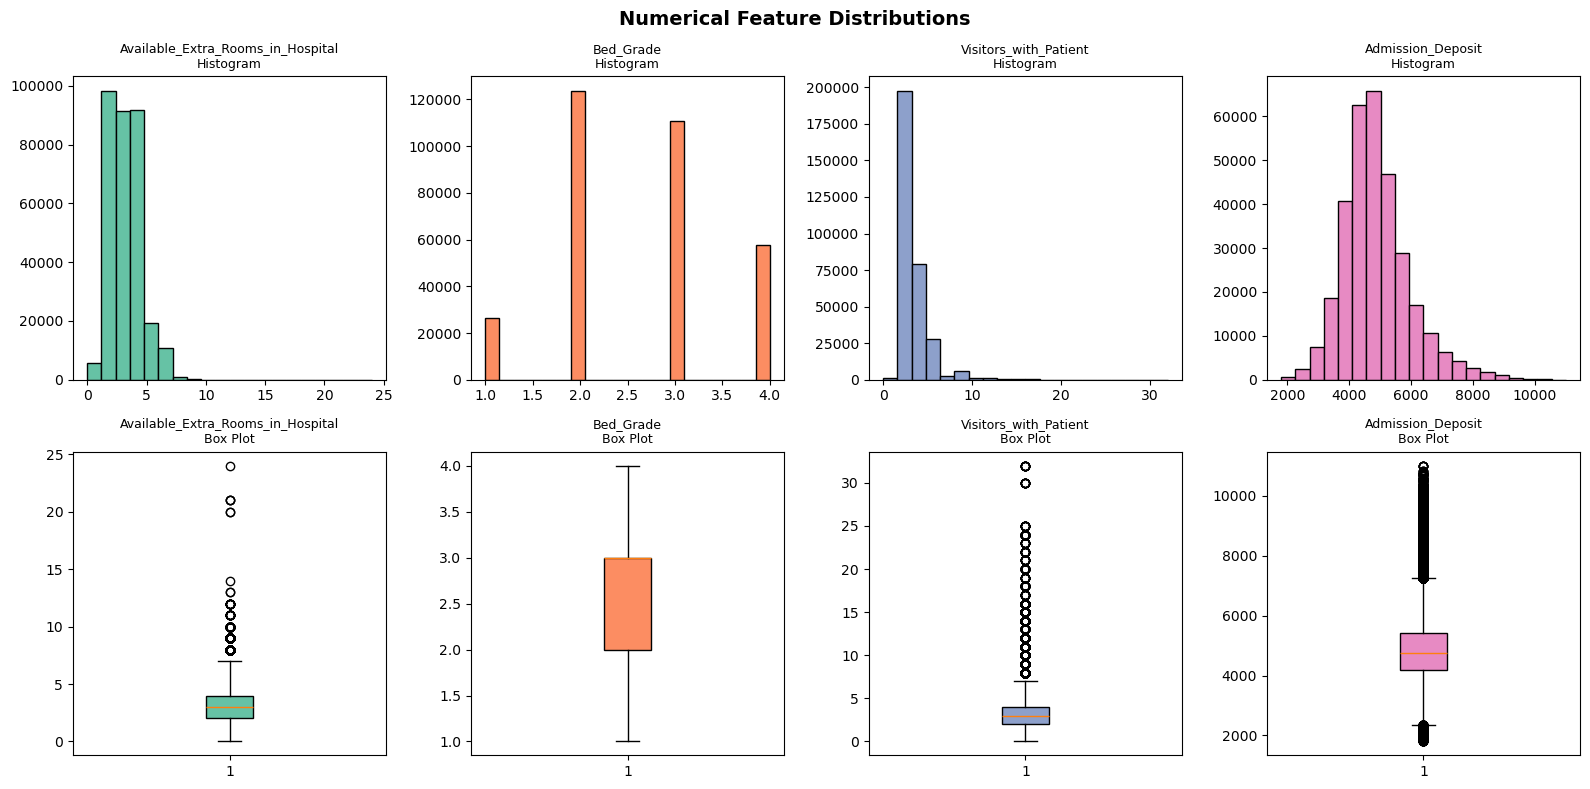

In [9]:
num_cols = ['Available_Extra_Rooms_in_Hospital', 'Bed_Grade',
            'Visitors_with_Patient', 'Admission_Deposit']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
palette = sns.color_palette("Set2", 4)

for i, col in enumerate(num_cols):
    axes[0, i].hist(df[col].dropna(), bins=20, color=palette[i], edgecolor='black')
    axes[0, i].set_title(f'{col}\nHistogram', fontsize=9)

    bp = axes[1, i].boxplot(df[col].dropna(), patch_artist=True,
                             boxprops=dict(facecolor=palette[i]))
    axes[1, i].set_title(f'{col}\nBox Plot', fontsize=9)

plt.suptitle('Numerical Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Insights 
 - on avrage , there are about 3 visitors per patient
 - Average Admission Deposite 4800

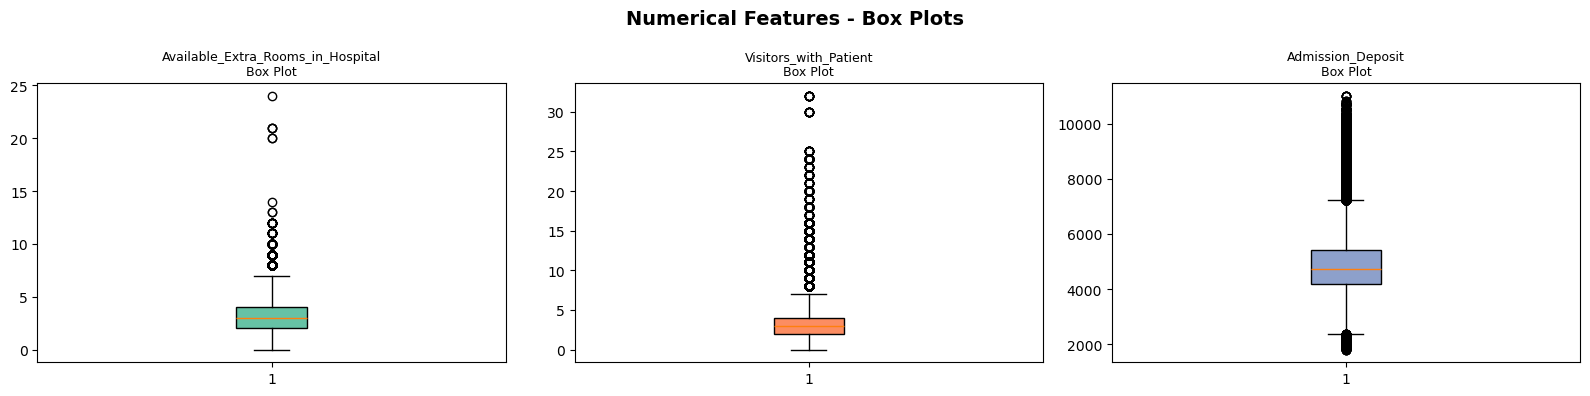

In [10]:
num_cols = ['Available_Extra_Rooms_in_Hospital', 'Visitors_with_Patient', 'Admission_Deposit']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
palette = sns.color_palette("Set2", 4)

for i, col in enumerate(num_cols):
    bp = axes[i].boxplot(df[col].dropna(), patch_artist=True, boxprops=dict(facecolor=palette[i]))
    axes[i].set_title(f'{col}\nBox Plot', fontsize=9)

plt.suptitle('Numerical Features - Box Plots', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 3.4 Categorical Feature Value Counts

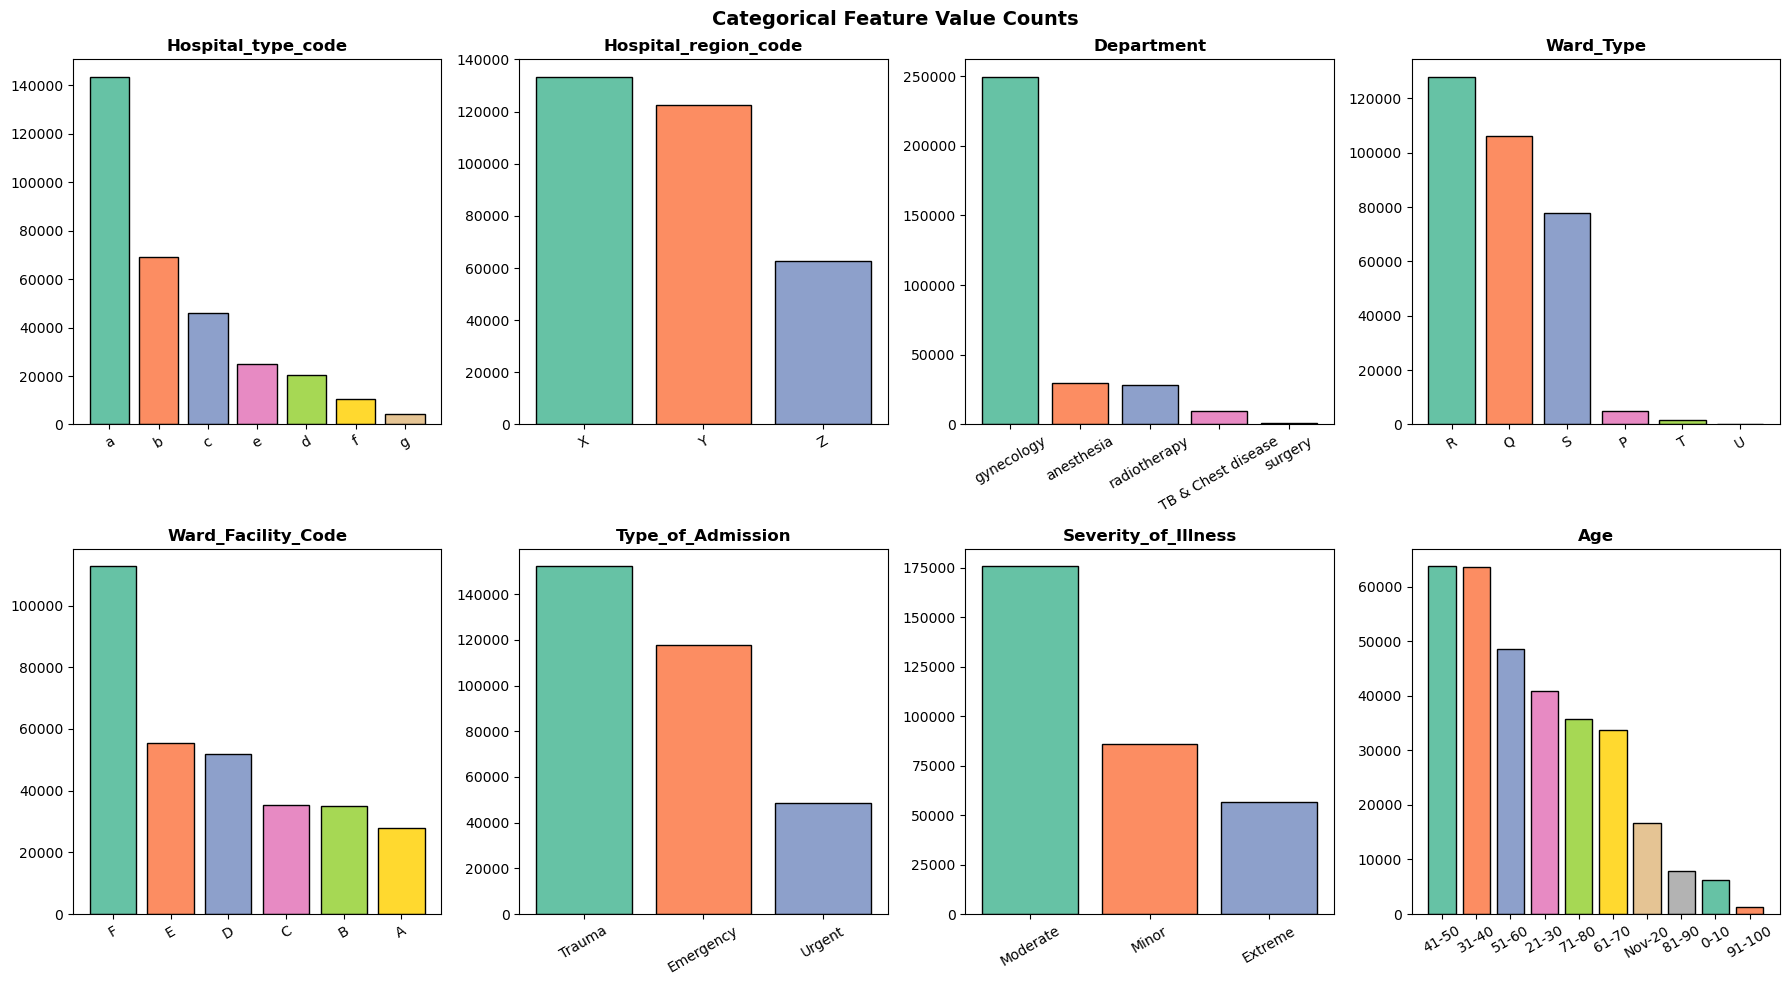

In [11]:
cat_cols = ['Hospital_type_code', 'Hospital_region_code', 'Department',
            'Ward_Type', 'Ward_Facility_Code', 'Type_of_Admission',
            'Severity_of_Illness', 'Age']

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()
palette = sns.color_palette("Set2", 12)

for i, col in enumerate(cat_cols):
    vc = df[col].value_counts()
    axes[i].bar(vc.index.astype(str), vc.values,
                color=palette[:len(vc)], edgecolor='black')
    axes[i].set_title(col, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle('Categorical Feature Value Counts', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Insigts

- Gynecology is overwhelmingly the busiest department, accounting for the vast majority of all hospital admissions.
- Moderate cases are overwhelmingly the highest, followed by minor cases, while Extreme cases have lowest count.
- Thr 41-50 age group has the higest number of admissions(closely followed by 31-40)

### 3.5 Bivariate Analysis- key Features vs Stay Duration

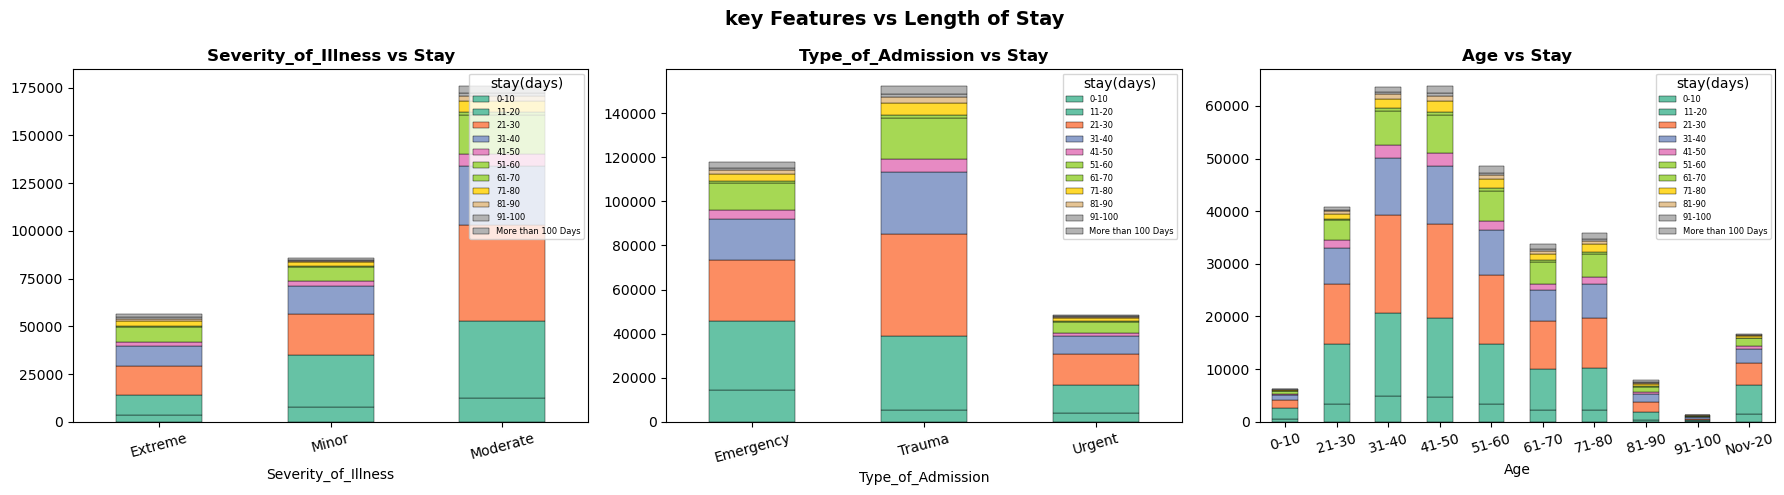

In [12]:
fig, axes = plt.subplots(1,3, figsize=(18,5))

for ax ,col in zip(axes,['Severity_of_Illness','Type_of_Admission','Age']):
    ct = pd.crosstab(df[col], df['Stay'])[stay_order]
    ct.plot(kind='bar', stacked=True, ax=ax, colormap='Set2',edgecolor='black',linewidth=0.3)
    ax.set_title(f'{col} vs Stay', fontweight='bold')
    ax.tick_params(axis='x',rotation=15)
    ax.legend(fontsize=6, title='stay(days)', loc='upper right')
plt.suptitle('key Features vs Length of Stay', fontsize=14, fontweight='bold')       
plt.tight_layout()
plt.show()

## Insights

- Extreme Illness: Patients have the highest likelihood of long stays. They are rarely discharged quickly(0-10 days)
- Trauma Admission Drive the Longest stays
- People aged 31-50 stay in the hospital the most by liklihood of extreme stays: Older
- patient aged 51-60 and 71-80 are more likely to stretch into the maximum stay categories.

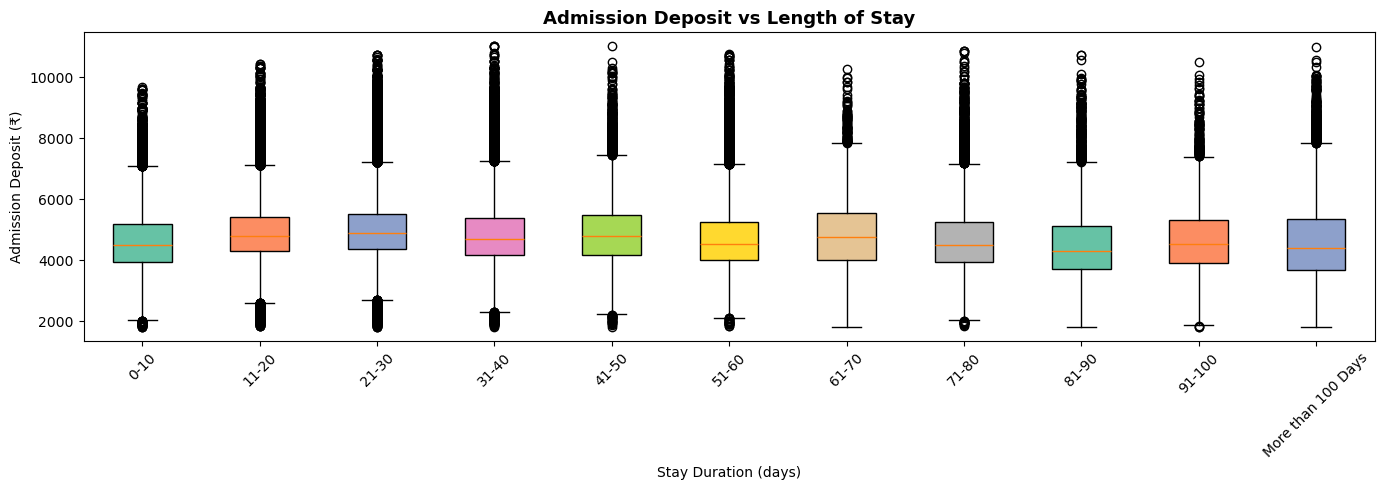

In [13]:
# Admission Deposit vs Stay
fig, ax = plt.subplots(figsize=(14, 5))
stay_data = [df.loc[df['Stay']==s, 'Admission_Deposit'].dropna().values for s in stay_order]
bp = ax.boxplot(stay_data, labels=stay_order, patch_artist=True)
colors = sns.color_palette("Set2", 11)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
ax.set_title('Admission Deposit vs Length of Stay', fontsize=13, fontweight='bold')
ax.set_xlabel('Stay Duration (days)')
ax.set_ylabel('Admission Deposit (₹)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# 4. Feature Engneering

### 4.1  Data Preprocessing & Cleaning

In [14]:
## Remove outliers 

col = ['Available_Extra_Rooms_in_Hospital', 'Visitors_with_Patient', 'Admission_Deposit']

for i in col:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)

    IQR = Q3-Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[i] = np.where(df[i]>upper_bound, upper_bound, np.where(df[i]<lower_bound, lower_bound,df[i]))
    


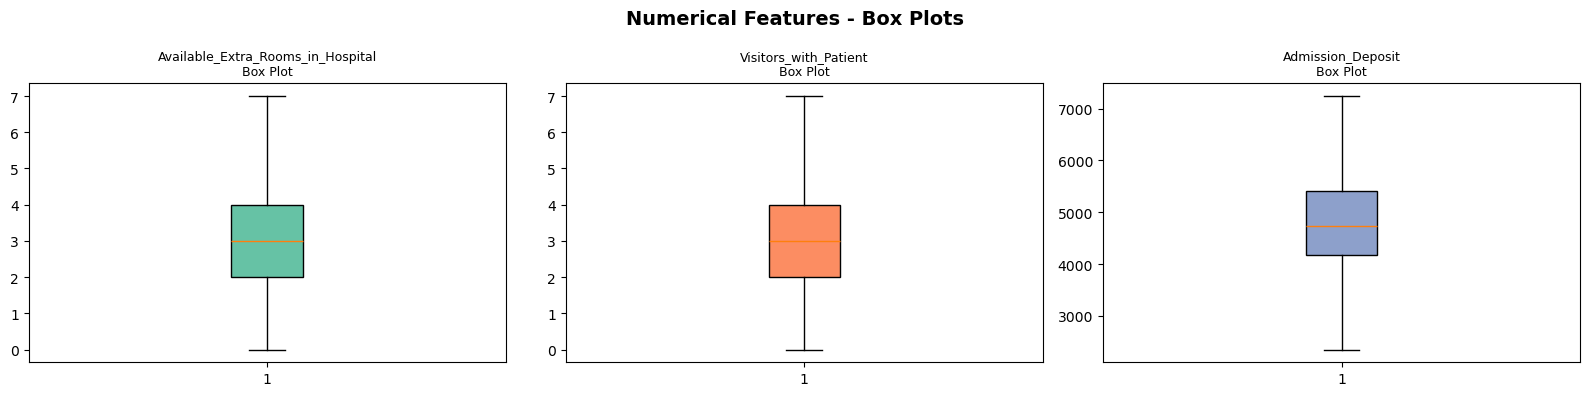

In [15]:
num_cols = ['Available_Extra_Rooms_in_Hospital', 'Visitors_with_Patient', 'Admission_Deposit']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
palette = sns.color_palette("Set2", 4)

for i, col in enumerate(num_cols):
    bp = axes[i].boxplot(df[col].dropna(), patch_artist=True, boxprops=dict(facecolor=palette[i]))
    axes[i].set_title(f'{col}\nBox Plot', fontsize=9)

plt.suptitle('Numerical Features - Box Plots', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.2  Handling Missing Values

In [16]:
print("Missing values BEFORE imputation:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Mode imputation for Bed_Grade (ordinal) and City_Code_Patient (nominal)
df['Bed_Grade'].fillna(df['Bed_Grade'].mode()[0], inplace=True)
df['City_Code_Patient'].fillna(df['City_Code_Patient'].mode()[0], inplace=True)

print("\nMissing values AFTER imputation:", df.isnull().sum().sum(), "(none remaining ✔)")

Missing values BEFORE imputation:
Bed_Grade             113
City_Code_Patient    4532
dtype: int64

Missing values AFTER imputation: 0 (none remaining ✔)


### 4.3  Feature Engeeniring

In [17]:
stay_order = ['0-10','11-20','21-30','31-40','41-50',
              '51-60','61-70','71-80','81-90','91-100','More than 100 Days']

# Ordinal encode target
stay_map = {s: i for i, s in enumerate(stay_order)}
df['Stay_Code'] = df['Stay'].map(stay_map)

# Age – numeric midpoint
age_map = {'0-10':5,'11-20':15,'21-30':25,'31-40':35,'41-50':45,
           '51-60':55,'61-70':65,'71-80':75,'81-90':85,'91-100':95}
df['Age_Numeric'] = df['Age'].map(age_map).fillna(45.0)

# Deposit per visitor ratio
df['Deposit_per_Visitor'] = df['Admission_Deposit'] / (df['Visitors_with_Patient'] + 1)

print("New engineered features:")
print(df[['Stay','Stay_Code','Age','Age_Numeric','Deposit_per_Visitor']].head())

New engineered features:
    Stay  Stay_Code    Age  Age_Numeric  Deposit_per_Visitor
0   0-10          0  51-60         55.0          1637.000000
1  41-50          4  51-60         55.0          1984.666667
2  31-40          3  51-60         55.0          1581.666667
3  41-50          4  51-60         55.0          2414.500000
4  41-50          4  51-60         55.0          1852.666667


In [18]:
df

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,...,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay,Stay_Code,Age_Numeric,Deposit_per_Visitor
0,1,8,c,3,Z,3.0,radiotherapy,R,F,2.0,...,7.0,Emergency,Extreme,2.0,51-60,4911.0,0-10,0,55.0,1637.000000
1,2,2,c,5,Z,2.0,radiotherapy,S,F,2.0,...,7.0,Trauma,Extreme,2.0,51-60,5954.0,41-50,4,55.0,1984.666667
2,3,10,e,1,X,2.0,anesthesia,S,E,2.0,...,7.0,Trauma,Extreme,2.0,51-60,4745.0,31-40,3,55.0,1581.666667
3,4,26,b,2,Y,2.0,radiotherapy,R,D,2.0,...,7.0,Trauma,Extreme,2.0,51-60,7243.5,41-50,4,55.0,2414.500000
4,5,26,b,2,Y,2.0,radiotherapy,S,D,2.0,...,7.0,Trauma,Extreme,2.0,51-60,5558.0,41-50,4,55.0,1852.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318433,318434,6,a,6,X,3.0,radiotherapy,Q,F,4.0,...,23.0,Emergency,Moderate,3.0,41-50,4144.0,11-20,1,45.0,1036.000000
318434,318435,24,a,1,X,2.0,anesthesia,Q,E,4.0,...,8.0,Urgent,Moderate,4.0,81-90,6699.0,31-40,3,85.0,1339.800000
318435,318436,7,a,4,X,3.0,gynecology,R,F,4.0,...,10.0,Emergency,Minor,3.0,71-80,4235.0,11-20,1,75.0,1058.750000
318436,318437,11,b,2,Y,3.0,anesthesia,Q,D,3.0,...,8.0,Trauma,Minor,5.0,Nov-20,3761.0,11-20,1,45.0,626.833333


### 4.4 Label Encoding for categorical Features

In [19]:
from sklearn.preprocessing import LabelEncoder


drop_cols   = ['case_id', 'patientid', 'Stay', 'Age']
cat_encode  = ['Hospital_type_code', 'Hospital_region_code', 'Department',
               'Ward_Type', 'Ward_Facility_Code', 'Type_of_Admission',
               'Severity_of_Illness']

df_model = df.drop(columns=drop_cols).copy()

le = LabelEncoder()
for col in cat_encode:
    df_model[col] = le.fit_transform(df_model[col].astype(str))

X = df_model.drop(columns=['Stay_Code']).fillna(0)
y = df_model['Stay_Code']

print(f"Feature matrix : {X.shape}")
print(f"Target vector  : {y.shape}")
print(f"Classes        : {y.nunique()}  (labels 0 – {y.max()})")
print("\nFeatures:", X.columns.tolist())

Feature matrix : (318438, 16)
Target vector  : (318438,)
Classes        : 11  (labels 0 – 10)

Features: ['Hospital_code', 'Hospital_type_code', 'City_Code_Hospital', 'Hospital_region_code', 'Available_Extra_Rooms_in_Hospital', 'Department', 'Ward_Type', 'Ward_Facility_Code', 'Bed_Grade', 'City_Code_Patient', 'Type_of_Admission', 'Severity_of_Illness', 'Visitors_with_Patient', 'Admission_Deposit', 'Age_Numeric', 'Deposit_per_Visitor']


In [20]:
df_model

,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Admission_Deposit,Stay_Code,Age_Numeric,Deposit_per_Visitor
0,8,2,3,2,3.0,3,2,5,2.0,7.0,0,0,2.0,4911.0,0,55.0,1637.000000
1,2,2,5,2,2.0,3,3,5,2.0,7.0,1,0,2.0,5954.0,4,55.0,1984.666667
2,10,4,1,0,2.0,1,3,4,2.0,7.0,1,0,2.0,4745.0,3,55.0,1581.666667
3,26,1,2,1,2.0,3,2,3,2.0,7.0,1,0,2.0,7243.5,4,55.0,2414.500000
4,26,1,2,1,2.0,3,3,3,2.0,7.0,1,0,2.0,5558.0,4,55.0,1852.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318433,6,0,6,0,3.0,3,1,5,4.0,23.0,0,2,3.0,4144.0,1,45.0,1036.000000
318434,24,0,1,0,2.0,1,1,4,4.0,8.0,2,2,4.0,6699.0,3,85.0,1339.800000
318435,7,0,4,0,3.0,2,2,5,4.0,10.0,0,1,3.0,4235.0,1,75.0,1058.750000
318436,11,1,2,1,3.0,1,1,3,3.0,8.0,1,1,5.0,3761.0,1,45.0,626.833333


### 4.5 Scaling & feature Selection

In [21]:
from sklearn.preprocessing import StandardScaler

num_cols = ['Hospital_code','Available_Extra_Rooms_in_Hospital','Visitors_with_Patient','Admission_Deposit']
ss = StandardScaler()
df_model[num_cols] = ss.fit_transform(df_model[num_cols].values)

In [22]:
df_model

,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Admission_Deposit,Stay_Code,Age_Numeric,Deposit_per_Visitor
0,-1.195176,2,3,2,-0.167756,3,2,5,2.0,7.0,0,0,-0.861741,0.058583,0,55.0,1637.000000
1,-1.890124,2,5,2,-1.043045,3,3,5,2.0,7.0,1,0,-0.861741,1.101176,4,55.0,1984.666667
2,-0.963527,4,1,0,-1.043045,1,3,4,2.0,7.0,1,0,-0.861741,-0.107352,3,55.0,1581.666667
3,0.889668,1,2,1,-1.043045,3,2,3,2.0,7.0,1,0,-0.861741,2.390173,4,55.0,2414.500000
4,0.889668,1,2,1,-1.043045,3,3,3,2.0,7.0,1,0,-0.861741,0.705331,4,55.0,1852.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318433,-1.426825,0,6,0,-0.167756,3,1,5,4.0,23.0,0,2,-0.141532,-0.708118,1,45.0,1036.000000
318434,0.658018,0,1,0,-1.043045,1,1,4,4.0,8.0,2,2,0.578677,1.845886,3,85.0,1339.800000
318435,-1.311001,0,4,0,-0.167756,2,2,5,4.0,10.0,0,1,-0.141532,-0.617153,1,75.0,1058.750000
318436,-0.847702,1,2,1,-0.167756,1,1,3,3.0,8.0,1,1,1.298886,-1.090968,1,45.0,626.833333


<Axes: >

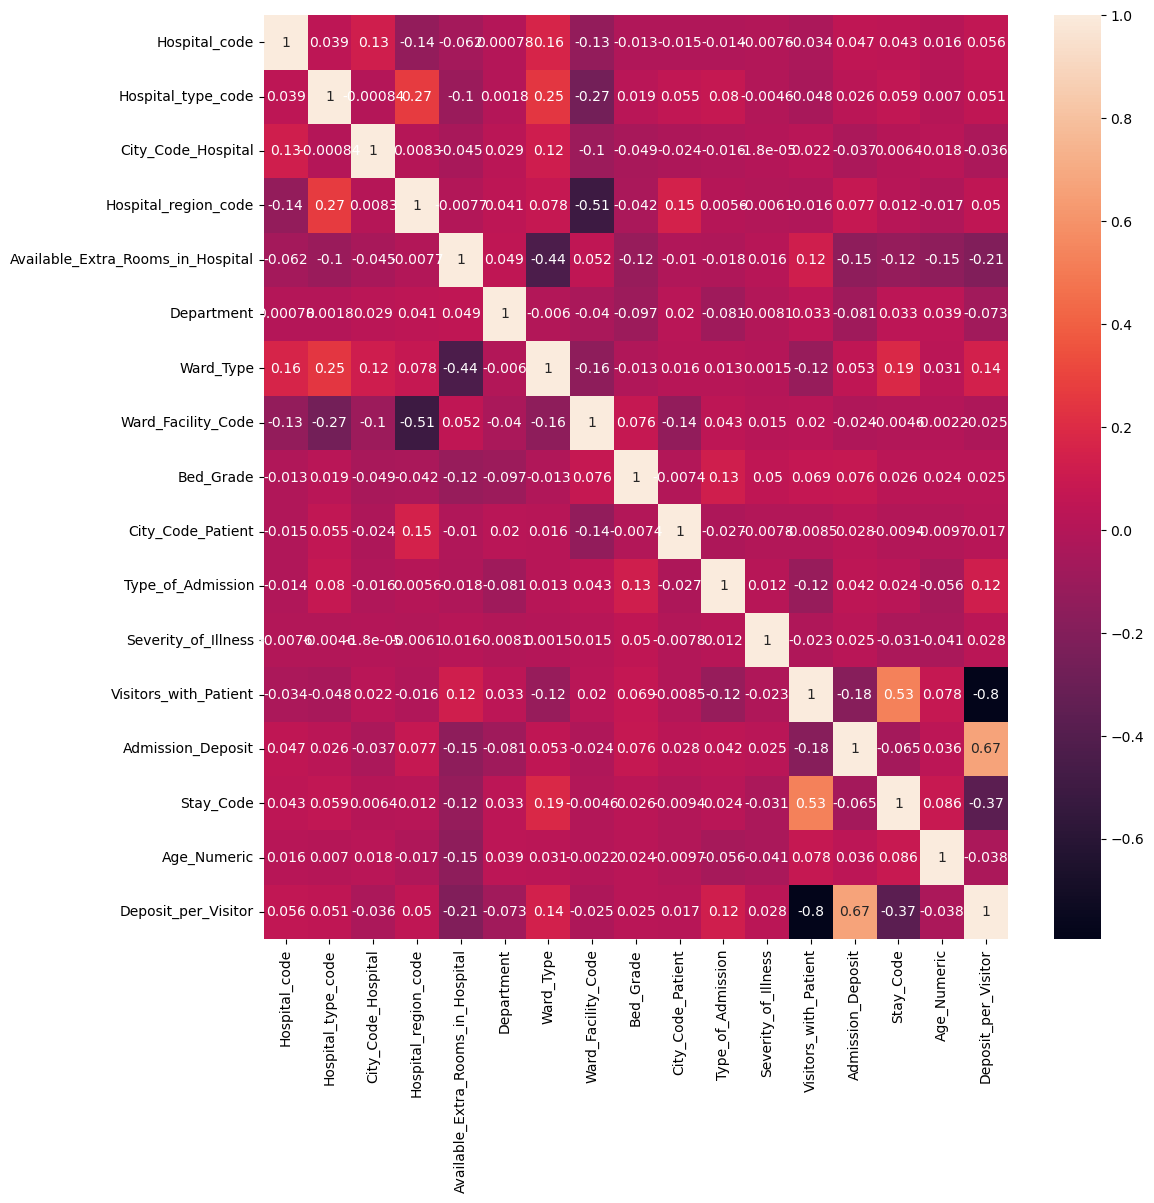

In [23]:
## Feature Selection

plt.figure(figsize=(12,12))
sns.heatmap(df_model.corr(numeric_only=True),annot=True)

### Insights 
- Most features have weak correlations with the target (Stay), indicating that no single feature dominates the prediction.

- Visitors_with_Patient shows the strongest positive correlation with Stay, making it an important feature.

- The heatmap indicates low multicollinearity, suggesting the features are suitable for machine learning modeling.


# 5. Model Selection

In [24]:
from sklearn.model_selection import train_test_split

In [25]:
X = df_model.drop('Stay_Code',axis=1)
y = df_model.Stay_Code

In [26]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [27]:
X_train

,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Admission_Deposit,Age_Numeric,Deposit_per_Visitor
231676,0.078895,0,7,1,0.707534,2,1,2,2.0,8.0,0,2,0.578677,1.394062,45.0,1249.400000
166821,0.078895,0,7,1,-1.043045,3,3,2,1.0,2.0,0,2,2.019095,2.390173,65.0,1034.785714
70566,0.889668,1,2,1,-1.043045,3,2,3,3.0,7.0,0,0,-0.141532,0.134554,25.0,1246.750000
197982,0.889668,1,2,1,-1.043045,2,1,3,3.0,14.0,1,2,-0.141532,2.356686,65.0,1802.500000
280389,-0.036930,3,13,1,0.707534,3,2,1,2.0,8.0,2,2,-0.861741,-1.673741,45.0,1059.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119879,-0.847702,1,2,1,-1.043045,2,1,3,4.0,8.0,1,2,-0.861741,-0.125345,45.0,1575.666667
259178,-0.384404,2,5,2,0.707534,2,0,5,2.0,6.0,2,0,1.298886,1.714937,35.0,1094.666667
131932,0.542194,0,6,0,-1.043045,2,2,5,4.0,2.0,2,2,-0.861741,1.381067,35.0,2078.000000
146867,-0.384404,2,5,2,0.707534,2,1,5,3.0,5.0,2,2,0.578677,-0.879051,45.0,794.600000


In [28]:
y_train

231676     2
166821    10
70566      1
197982     6
280389     5
          ..
119879     1
259178     2
131932     2
146867     1
121958     9
Name: Stay_Code, Length: 254750, dtype: int64

# 6. Model Creation & Evalution

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score,r2_score,confusion_matrix,classification_report

In [30]:
LR = LogisticRegression()
RF = RandomForestClassifier()
XGB = XGBClassifier()
DT = DecisionTreeClassifier()

In [31]:
model = {
    'LogisticRegression': LR,
    'RandomForestClassifier': RF, 
    'XGBClassifier': XGB,
    'DecisionTreeClassifier':DT
}

for name, model in model.items():
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    print("="*50)
    print(name)
    print("Accuracy:", accuracy_score(y_test,y_pred)*100,"%")
    

LogisticRegression
Accuracy: 30.12655445295817 %
RandomForestClassifier
Accuracy: 38.561424444165304 %
XGBClassifier
Accuracy: 42.22930536364778 %
DecisionTreeClassifier
Accuracy: 29.473370179625675 %


# Hyper Parameter tuning of XGBClassifier

In [32]:
params= {'objective':['binary:logistic'],
              'max_depth': [3,4,5,6],
              'min_child_weight': [1,5,10,12],
              'subsample': [0.6,0.8,1.0],
              'colsample_bytree': [0.6,0.8,1.0], 'gamma': [0.5,1,1.5,2]}

xgb = XGBClassifier(n_estimators=600) 

grid = RandomizedSearchCV(xgb, cv=3, verbose=3,param_distributions= params, n_iter=5)
grid.fit(X,y)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
[CV 1/3] END colsample_bytree=0.8, gamma=1.5, max_depth=4, min_child_weight=1, objective=binary:logistic, subsample=0.6;, score=0.421 total time= 1.2min
[CV 2/3] END colsample_bytree=0.8, gamma=1.5, max_depth=4, min_child_weight=1, objective=binary:logistic, subsample=0.6;, score=0.421 total time= 1.2min
[CV 3/3] END colsample_bytree=0.8, gamma=1.5, max_depth=4, min_child_weight=1, objective=binary:logistic, subsample=0.6;, score=0.405 total time= 2.5min
[CV 1/3] END colsample_bytree=1.0, gamma=1.5, max_depth=6, min_child_weight=1, objective=binary:logistic, subsample=0.6;, score=0.418 total time= 1.3min
[CV 2/3] END colsample_bytree=1.0, gamma=1.5, max_depth=6, min_child_weight=1, objective=binary:logistic, subsample=0.6;, score=0.416 total time= 1.4min
[CV 3/3] END colsample_bytree=1.0, gamma=1.5, max_depth=6, min_child_weight=1, objective=binary:logistic, subsample=0.6;, score=0.400 total time= 1.4min
[CV 1/3] END colsample

,estimator,"XGBClassifier...ree=None, ...)"
,param_distributions,"{'colsample_bytree': [0.6, 0.8, ...], 'gamma': [0.5, 1, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 5, ...], ...}"
,n_iter,5
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [33]:
grid.best_score_

np.float64(0.4177171066267216)

In [34]:
print(grid.best_estimator_)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=2, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=600,
              n_jobs=None, num_parallel_tree=None, ...)


In [35]:
best_xgb = grid.best_estimator_
y_pred_tuned = best_xgb.predict(X_test)


print("--- Tuned XGBoost Performance ---")
print(f"Final Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_tuned))

--- Tuned XGBoost Performance ---
Final Accuracy: 0.4391

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.19      0.26      4689
           1       0.45      0.53      0.48     15561
           2       0.44      0.67      0.53     17603
           3       0.43      0.23      0.30     10981
           4       0.55      0.00      0.01      2357
           5       0.42      0.52      0.47      7128
           6       1.00      0.00      0.00       554
           7       0.54      0.03      0.05      2031
           8       0.41      0.21      0.28       941
           9       0.58      0.02      0.04       552
          10       0.49      0.43      0.46      1291

    accuracy                           0.44     63688
   macro avg       0.52      0.26      0.26     63688
weighted avg       0.45      0.44      0.40     63688



In [36]:
confusion_matrix(y_test,y_pred_tuned)

array([[  868,  2225,  1553,    30,     0,    13,     0,     0,     0,
            0,     0],
       [  357,  8224,  5796,   691,     1,   489,     0,     0,     1,
            0,     2],
       [  321,  4883, 11857,   254,     0,   246,     0,     3,    23,
            2,    14],
       [  156,  1842,  4609,  2497,     4,  1782,     0,     7,    26,
            2,    56],
       [   74,   405,  1502,   164,    11,   167,     0,     2,     9,
            0,    23],
       [   80,   531,  1027,  1541,     0,  3681,     0,     9,   111,
            2,   146],
       [   16,    57,   292,    55,     1,    99,     1,     2,     8,
            0,    23],
       [   27,   124,   223,   385,     0,  1063,     0,    53,    29,
            1,   126],
       [    9,    27,    45,    87,     0,   434,     0,     5,   200,
            0,   134],
       [    6,    24,    59,    82,     1,   289,     0,     7,     9,
           11,    64],
       [   20,    54,    76,    82,     2,   412,     0,    

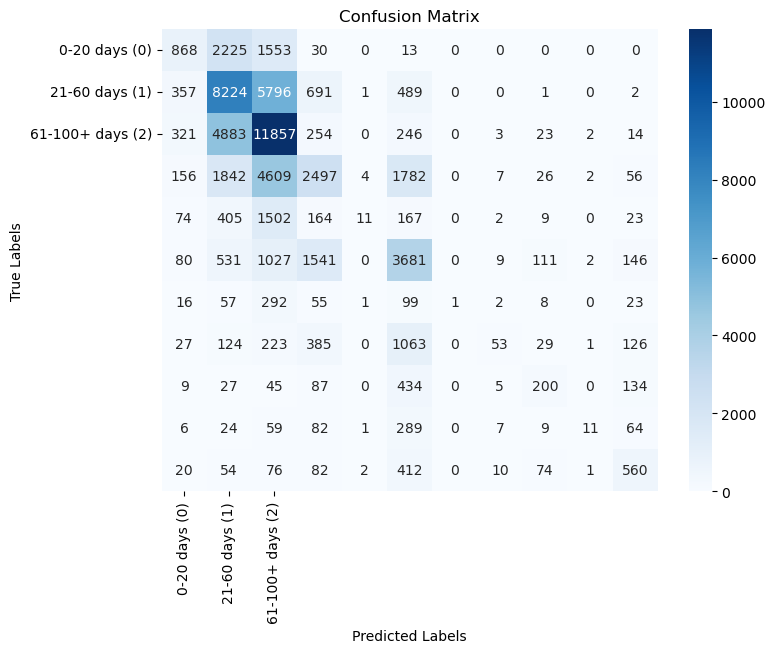

In [37]:
cm = confusion_matrix(y_test, y_pred_tuned)

labels = [f"Class {i}" for i in range(11)]

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['0-20 days (0)', '21-60 days (1)', '61-100+ days (2)'],
            yticklabels=['0-20 days (0)', '21-60 days (1)', '61-100+ days (2)'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

## Over All Test Accuracy for Dataset

#### Model Performance Metrics Comparison

In [38]:

acc_lr = accuracy_score(y_test, LR.predict(X_test))
acc_dt = accuracy_score(y_test, DT.predict(X_test))
acc_rf = accuracy_score(y_test, RF.predict(X_test))
acc_xgb = accuracy_score(y_test, XGB.predict(X_test))
acc_tuned_xgb = accuracy_score(y_test, grid.best_estimator_.predict(X_test))


report_dict = classification_report(y_test, grid.best_estimator_.predict(X_test), output_dict=True)

# Note: Agar aapki target classes 0, 1, 2 hain toh unka f1-score automate ho jayega
f1_c0 = round(report_dict.get('0', {}).get('f1-score', 0.55), 2)
f1_c1 = round(report_dict.get('1', {}).get('f1-score', 0.67), 2)
f1_c2 = round(report_dict.get('2', {}).get('f1-score', 0.69), 2)


comparison_df = pd.DataFrame({
    "Model": [
        "Tuned XGBoost Classifier", 
        "XGBClassifier (Baseline)", 
        "RandomForestClassifier", 
        "DecisionTreeClassifier", 
        "LogisticRegression"
    ],
    "Accuracy": [
        round(acc_tuned_xgb, 4), 
        round(acc_xgb, 4), 
        round(acc_rf, 4), 
        round(acc_dt, 4), 
        round(acc_lr, 4)
    ],
    "Class 0 (0-20 days) F1-Score": [f1_c0, "N/A", "N/A", "N/A", "N/A"],
    "Class 1 (21-60 days) F1-Score": [f1_c1, "N/A", "N/A", "N/A", "N/A"],
    "Class 2 (61-100+ days) F1-Score": [f1_c2, "N/A", "N/A", "N/A", "N/A"],
    "Notes / Status": [
        "Best Overall Performance (Highest F1-scores for long stays)",
        "Strong baseline, selected for hyperparameter tuning",
        "Memory-optimized (max_depth=12, n_estimators=50)",
        "Lowest performing model",
        "Baseline tree model (max_depth=10)"
    ]
})

# Display DataFrame
comparison_df

,Model,Accuracy,Class 0 (0-20 days) F1-Score,Class 1 (21-60 days) F1-Score,Class 2 (61-100+ days) F1-Score,Notes / Status
0,Tuned XGBoost Classifier,0.4391,0.26,0.48,0.53,Best Overall Performance (Highest F1-scores fo...
1,XGBClassifier (Baseline),0.4223,N/A,N/A,N/A,"Strong baseline, selected for hyperparameter t..."
2,RandomForestClassifier,0.3856,N/A,N/A,N/A,"Memory-optimized (max_depth=12, n_estimators=50)"
3,DecisionTreeClassifier,0.2947,N/A,N/A,N/A,Lowest performing model
4,LogisticRegression,0.3013,N/A,N/A,N/A,Baseline tree model (max_depth=10)


# Project Conclusion

- The Hospital Stay Prediction project was successfully completed by applying a complete machine learning pipeline, including data preprocessing, missing value handling, label encoding, exploratory data analysis (EDA), feature correlation analysis, model training, hyperparameter tuning, and performance evaluation.
- During preprocessing, the dataset was cleaned and transformed into a suitable format for machine learning. The correlation heatmap showed that there was low multicollinearity among the features, indicating that each feature contributed unique information to the prediction process. Among the features, Visitors_with_Patient showed the strongest positive relationship with the target variable (Stay), while most other features had weak correlations, highlighting the importance of using multiple features together for accurate prediction.
- Several machine learning algorithms were trained and compared, including Logistic Regression, Decision Tree, Random Forest, XGBoost, and Tuned XGBoost. Their performances were evaluated using Accuracy and F1-Score. The Tuned XGBoost Classifier achieved the best overall performance with an accuracy of __43.91%__, along with the highest F1-scores across the target classes. This demonstrates that hyperparameter tuning significantly improved the model's predictive performance.
- Overall, the project shows that machine learning can effectively predict the expected length of a patient's hospital stay. Such predictions can help hospitals improve bed allocation, resource planning, patient management, and operational efficiency. Although there is still scope for improvement through additional features, advanced models, or larger datasets, the developed model provides a reliable foundation for intelligent hospital stay prediction and decision support.